In [1]:
# import libraries for spatial data, tables, and plotting
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# import file paths, image tools, and map formatting tools
from pathlib import Path
import json
import re
import textwrap
import rasterio
import matplotlib.patheffects as path_effects
from matplotlib.patches import Rectangle
from matplotlib import font_manager
from IPython.display import display


In [3]:
# locate the course folder from the current working directory
working_dir = Path.cwd().resolve()
course_dir = next(
    (folder if folder.name == "_fall2026" else folder / "_fall2026"
     for folder in [working_dir, *working_dir.parents]
     if (folder.name == "_fall2026" and (folder / "Assignments").is_dir())
     or (folder / "_fall2026" / "Assignments").is_dir()),
    None
)
if course_dir is None:
    raise FileNotFoundError("Run the notebook inside the course repository.")


In [4]:
# define the assignment, source data, and output paths
assignment_dir = course_dir / "Assignments" / "Assignment 02 Making Data + Narrative Building"
data_dir = assignment_dir / "data"
world_dir = data_dir / "historical/worldwide"
atlantic_dir = data_dir / "historical/atlantic"
world_gpkg = world_dir / "worldwide_cables.gpkg"
output_pdf = assignment_dir / "Output" / "Assignment02-Map01-UnseenConnections.pdf"
derived_dir = assignment_dir / "Output"
derived_dir.mkdir(parents=True, exist_ok=True)
print("Data folder:", data_dir)
print("Map export:", output_pdf)


Data folder: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignments/Assignment 02 Making Data + Narrative Building/data
Map export: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignments/Assignment 02 Making Data + Narrative Building/Output/Assignment02-Map01-UnseenConnections.pdf


In [5]:
# load the saved timeline extraction
# reuse the local source snapshot rather than requesting new data
with open(world_dir / "source_records.json", encoding="utf-8") as source_file:
    source_rows = json.load(source_file)


In [6]:
# load the normalized cable catalogue
catalogue = pd.read_csv(world_dir / "complete_catalogue.csv", dtype="string")
print("Saved extracted rows:", len(source_rows))
print("Normalized catalogue entries:", len(catalogue))
display(catalogue.head())


Saved extracted rows: 2309
Normalized catalogue entries: 2309


,row_id,cable_id,year,route,status,mapped_points,unresolved_parts,source
0,1,#001,1845,Laid between HMS Blake and HMS Pique in Portsm...,voce della cronologia; operativita non verificata,0,Laid between HMS Blake and HMS Pique in Portsm...,https://atlantic-cable.com/Cables/CableTimeLin...
1,2,#002,1849,Laid between Princess Clementine and the shore...,voce della cronologia; operativita non verificata,0,Laid between Princess Clementine and the shore...,https://atlantic-cable.com/Cables/CableTimeLin...
2,3,#003,1850,"Dover, England - Calais, France",voce della cronologia; operativita non verificata,2,<NA>,https://atlantic-cable.com/Cables/CableTimeLin...
3,4,#004,1851,"Dover, England - Calais, France (St Margarets ...",voce della cronologia; operativita non verificata,2,<NA>,https://atlantic-cable.com/Cables/CableTimeLin...
4,5,#005,1852,"Holyhead, Wales - Howth, Ireland",voce della cronologia; operativita non verificata,2,<NA>,https://atlantic-cable.com/Cables/CableTimeLin...


In [7]:
# inspect one original record alongside the normalized table fields
print("Example extracted record:")
print(source_rows[0])
print("\nCatalogue fields:")
print(catalogue.columns.tolist())

# count records with no mapped locations without discarding them
catalogue["mapped_points"] = pd.to_numeric(catalogue["mapped_points"], errors="coerce")
print("\nEntries without mapped points:", catalogue["mapped_points"].eq(0).sum())


Example extracted record:
{'cells': ['1951', 'Cable laid across the Toyogo Waterway between Kanzaki and Yasuki', '?', 'Japanese Government', '\xa0', 'System 46.6 km.\xa0 14 strand lead sheathed cable', '\xa0'], 'source': 'https://atlantic-cable.com/Cables/CableTimeLine/index1951.htm'}

Catalogue fields:
['row_id', 'cable_id', 'year', 'route', 'status', 'mapped_points', 'unresolved_parts', 'source']

Entries without mapped points: 507


In [8]:
# inspect the available spatial and non-spatial tables
print(gpd.list_layers(world_gpkg).to_string(index=False))


                            name geometry_type
localita_mondiali_tutti_gli_anni         Point
     localita_mondiali_1858_1900         Point
                  punti_per_cavo         Point
          catalogo_tutte_le_voci           NaN
                catalogo_id_cavi           NaN
             parti_da_verificare           NaN


In [9]:
# load the saved geocoding results and cable-place relationships
# coordinates represent localities rather than exact historical landings
saved_locations = gpd.read_file(world_gpkg, layer="localita_mondiali_tutti_gli_anni")
cable_points = gpd.read_file(world_gpkg, layer="punti_per_cavo")
unresolved = gpd.read_file(world_gpkg, layer="parti_da_verificare")
print("\nGeocoded locations:", len(saved_locations))
print("Cable-place records:", len(cable_points))
print("Unresolved source fragments:", len(unresolved))
saved_locations.head()



Geocoded locations: 1521
Cable-place records: 4288
Unresolved source fragments: 2075


,place_id,city,country,continent,cable_ids,n_cables,years,label,coord_source,precision,source,geometry
0,tg:aasiaat-greenland,Aasiaat,GL,NA,#2026,1,2017,Aasiaat\n#2026,https://www.submarinecablemap.com/api/v3/landi...,Localita rappresentativa; non approdo storico ...,https://atlantic-cable.com/Cables/CableTimeLin...,POINT (-52.85912 68.70697)
1,tg:aberdeen-united-kingdom,Aberdeen,GB,EU,#1261 #1763,2,1954; 2001?,Aberdeen\n#1261 #1763,https://www.submarinecablemap.com/api/v3/landi...,Localita rappresentativa; non approdo storico ...,https://atlantic-cable.com/Cables/CableTimeLin...,POINT (-2.10679 57.15382)
2,2293538,Abidjan,CI,AF,#1419 #1791 #1905 #1944 #2119 #2156,6,1977; 2002; 2010; 2012; 2021; 2023,Abidjan\n#1419 #1791 #1905 #1944 #2119\n#2156,https://www.geonames.org/2293538,Localita rappresentativa; non approdo storico ...,https://atlantic-cable.com/Cables/CableTimeLin...,POINT (-4.00167 5.35444)
3,tg:abu-dhabi-united-arab-emirates,Abu Dhabi,AE,AS,#1809,1,2004,Abu Dhabi\n#1809,https://www.submarinecablemap.com/api/v3/landi...,Localita rappresentativa; non approdo storico ...,https://atlantic-cable.com/Cables/CableTimeLin...,POINT (54.41888 24.44379)
4,tg:abu-talat-egypt,Abu Talat,EG,AF,#2027,1,2017,Abu Talat\n#2027,https://www.submarinecablemap.com/api/v3/landi...,Localita rappresentativa; non approdo storico ...,https://atlantic-cable.com/Cables/CableTimeLin...,POINT (29.70249 31.07185)


In [10]:
# convert the saved coordinates into an ordinary attribute table
saved_locations = saved_locations.to_crs("EPSG:4326")
location_table = pd.DataFrame(saved_locations.drop(columns="geometry"))
location_table["longitude"] = saved_locations.geometry.x
location_table["latitude"] = saved_locations.geometry.y


In [11]:
# check identifiers and coordinate ranges before making spatial data
assert location_table["place_id"].is_unique
assert location_table["longitude"].between(-180, 180).all()
assert location_table["latitude"].between(-90, 90).all()
location_table[["place_id", "city", "years", "longitude", "latitude", "coord_source"]].head()


,place_id,city,years,longitude,latitude,coord_source
0,tg:aasiaat-greenland,Aasiaat,2017,-52.859117,68.706972,https://www.submarinecablemap.com/api/v3/landi...
1,tg:aberdeen-united-kingdom,Aberdeen,1954; 2001?,-2.106789,57.153820,https://www.submarinecablemap.com/api/v3/landi...
2,2293538,Abidjan,1977; 2002; 2010; 2012; 2021; 2023,-4.001670,5.354440,https://www.geonames.org/2293538
3,tg:abu-dhabi-united-arab-emirates,Abu Dhabi,2004,54.418883,24.443786,https://www.submarinecablemap.com/api/v3/landi...
4,tg:abu-talat-egypt,Abu Talat,2017,29.702495,31.071849,https://www.submarinecablemap.com/api/v3/landi...


In [12]:
# create point geometries from longitude and latitude
locations = gpd.GeoDataFrame(
    location_table.copy(),
    geometry=gpd.points_from_xy(location_table["longitude"], location_table["latitude"]),
    crs="EPSG:4326"
)

# preserve the cable IDs that connect each place to the source catalogue
print("Coordinate system:", locations.crs)
print("Unique locations:", len(locations))
locations[["city", "cable_ids", "years", "geometry"]].head()


Coordinate system: EPSG:4326
Unique locations: 1521


,city,cable_ids,years,geometry
0,Aasiaat,#2026,2017,POINT (-52.85912 68.70697)
1,Aberdeen,#1261 #1763,1954; 2001?,POINT (-2.10679 57.15382)
2,Abidjan,#1419 #1791 #1905 #1944 #2119 #2156,1977; 2002; 2010; 2012; 2021; 2023,POINT (-4.00167 5.35444)
3,Abu Dhabi,#1809,2004,POINT (54.41888 24.44379)
4,Abu Talat,#2027,2017,POINT (29.70249 31.07185)


In [13]:
# extract the earliest recorded year without assuming that dates are exact
locations["first_year"] = locations["years"].fillna("").apply(
    lambda value: min(map(int, re.findall(r"\b\d{4}\b", value)))
    if re.findall(r"\b\d{4}\b", value) else np.nan
)


In [14]:
# classify locations using the reference narrative's 1988 threshold
# the QGIS formula uses 1987; use 1988 here so the text and classification agree
# dates are catalogue records, not verified operational dates
cutoff_year = 1988
locations["period"] = "Unknown year"
locations.loc[locations["first_year"] < cutoff_year, "period"] = "Before 1988"
locations.loc[locations["first_year"] >= cutoff_year, "period"] = "1988 onward"


In [15]:
# assign colors to the historical periods
period_colors = {"Before 1988": "#ff0000", "1988 onward": "#0000ff", "Unknown year": "#ffffff"}
locations["map_color"] = locations["period"].map(period_colors)
print(locations["period"].value_counts())
locations[["city", "years", "first_year", "period"]].head()


period
1988 onward     909
Before 1988     599
Unknown year     13
Name: count, dtype: int64


,city,years,first_year,period
0,Aasiaat,2017,2017.0,1988 onward
1,Aberdeen,1954; 2001?,1954.0,Before 1988
2,Abidjan,1977; 2002; 2010; 2012; 2021; 2023,1977.0,Before 1988
3,Abu Dhabi,2004,2004.0,1988 onward
4,Abu Talat,2017,2017.0,1988 onward


In [16]:
# inspect all mapped places for one source cable entry
example_id = "#003"
example_places = cable_points.loc[cable_points["cable_id"].eq(example_id)]
display(example_places[["cable_id", "year", "city", "route", "status"]])

# inspect the corresponding catalogue record
catalogue.loc[catalogue["cable_id"].eq(example_id)]


,cable_id,year,city,route,status
0,#003,1850,Dover,"Dover, England - Calais, France",voce della cronologia; operativita non verificata
1,#003,1850,Calais,"Dover, England - Calais, France",voce della cronologia; operativita non verificata


,row_id,cable_id,year,route,status,mapped_points,unresolved_parts,source
2,3,#003,1850,"Dover, England - Calais, France",voce della cronologia; operativita non verificata,2,<NA>,https://atlantic-cable.com/Cables/CableTimeLin...


In [17]:
# load the cable network, land outlines, and twenty-degree grid
# cable lines come from a separate geometry dataset, not the historical point IDs
cables = gpd.read_file(data_dir / "reference/cable_network/cable-geo.json")
land = gpd.read_file(data_dir / "reference/land/ne_10m_land/ne_10m_land.shp")
graticules = gpd.read_file(data_dir / "reference/graticules/ne_10m_graticules_all/ne_10m_graticules_20.shp")

# load the separately digitized historical Atlantic cable
historical_cable = gpd.read_file(data_dir / "archival/digitized_routes/1858 - Atlantic Cable.shp")
print("Cable features:", len(cables))
print("Historical cable features:", len(historical_cable))
print("Cable fields:", cables.columns.tolist())


Cable features: 527
Historical cable features: 1
Cable fields: ['id', 'name', 'color', 'feature_id', 'coordinates', 'geometry']


In [18]:
# inspect coordinate systems before combining the layers
for name, layer in [("Locations", locations), ("Cables", cables),
                    ("Land", land), ("Grid", graticules),
                    ("Historical cable", historical_cable)]:
    print(name, layer.crs)


Locations EPSG:4326
Cables EPSG:4326
Land EPSG:4326
Grid EPSG:4326
Historical cable EPSG:4326


In [19]:
# use longitude and latitude to reproduce the reference's rectangular world map
target_crs = "EPSG:4326"
cables = cables.to_crs(target_crs)
land = land.to_crs(target_crs)
graticules = graticules.to_crs(target_crs)
historical_cable = historical_cable.to_crs(target_crs)


In [20]:
# read a small preview of the georeferenced historical image
historical_image_path = data_dir / "archival/images/1858 - Atlantic Cable Route.tif"
with rasterio.open(historical_image_path) as source:
    print("Image CRS:", source.crs)
    print("Image bounds:", source.bounds)
    preview_scale = max(source.width, source.height) / 1200
    preview = source.read(
        out_shape=(source.count, max(1, round(source.height / preview_scale)),
                   max(1, round(source.width / preview_scale)))
    )
    image_extent = (source.bounds.left, source.bounds.right,
                    source.bounds.bottom, source.bounds.top)
    image_crs = source.crs


Image CRS: EPSG:4326
Image bounds: BoundingBox(left=-91.52882043880227, bottom=28.74064022850876, right=18.79570893330333, top=65.26054509865116)


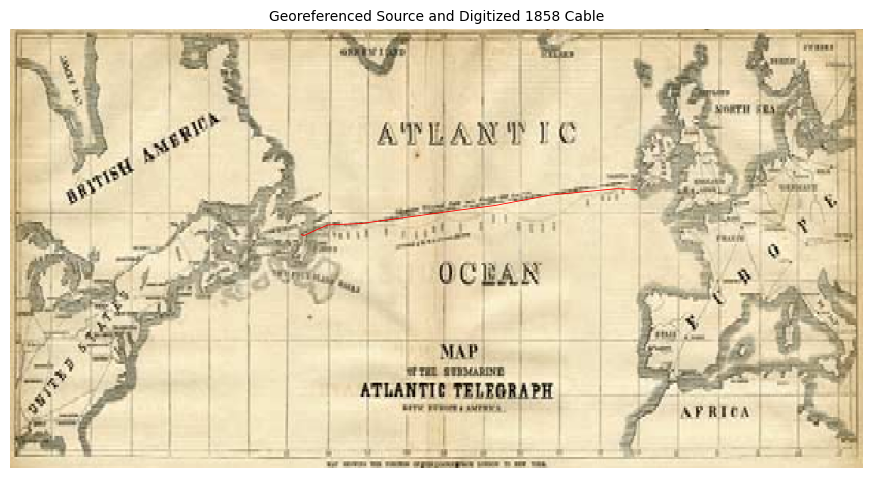

In [21]:
# overlay the digitized cable in the image's coordinate system
fig, ax = plt.subplots(figsize=(11, 6))
if preview.shape[0] >= 3:
    ax.imshow(np.moveaxis(preview[:3], 0, -1), extent=image_extent)
else:
    ax.imshow(preview[0], extent=image_extent, cmap="gray")
historical_cable.to_crs(image_crs).plot(ax=ax, color="#ff0000", linewidth=0.6)
ax.set_title("Georeferenced Source and Digitized 1858 Cable", fontsize=10)
ax.set_axis_off()
plt.show()


In [22]:
# load the bathymetric polygons in their original coordinate system
bathymetry_dir = data_dir / "reference/bathymetry/ne_10m_bathymetry_all"
bathymetry_files = sorted(
    path for path in bathymetry_dir.glob("*.shp")
    if int(path.stem.rsplit("_", 1)[1]) >= 1000
)


In [23]:
# load the selected bathymetry layers
bathymetry_parts = []
for file_path in bathymetry_files:
    part = gpd.read_file(file_path).to_crs(target_crs)
    part["depth_m"] = int(file_path.stem.rsplit("_", 1)[1])
    bathymetry_parts.append(part)


In [24]:
# combine the bathymetry layers
bathymetry = gpd.GeoDataFrame(
    pd.concat(bathymetry_parts, ignore_index=True),
    geometry="geometry", crs=target_crs
)
print("Depth layers:", len(bathymetry_files))
print("Bathymetry features:", len(bathymetry))


Depth layers: 10
Bathymetry features: 5237


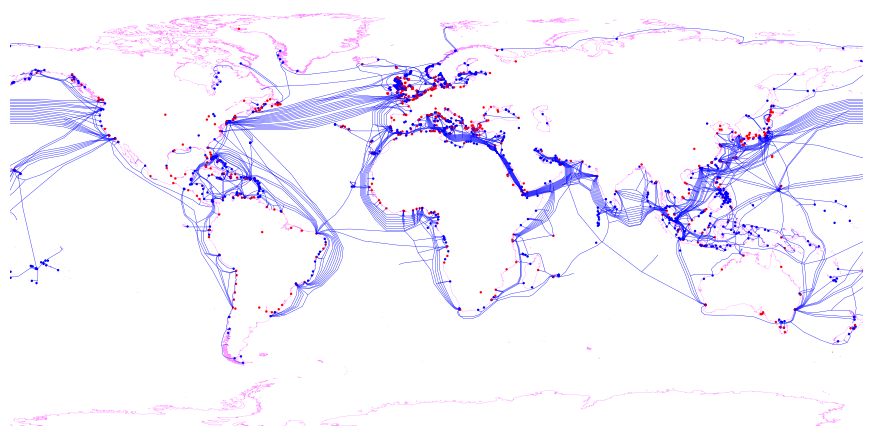

In [25]:
# draw a quick preview of the network and historical locations
fig, ax = plt.subplots(figsize=(11, 6))
land.plot(ax=ax, facecolor="white", edgecolor="#ff8fff", linewidth=0.2)
cables.plot(ax=ax, color="#0000ff", linewidth=0.25)
locations.plot(ax=ax, color=locations["map_color"], edgecolor="none", markersize=3)
ax.set_xlim(-160, 178)
ax.set_ylim(-80, 85)
ax.set_aspect("equal")
ax.set_axis_off()
plt.show()


In [26]:
# register a local font and keep PDF text editable
font_candidates = list((course_dir / "Assignments").glob("*/data/fonts/Roboto-Light.ttf"))
if font_candidates:
    font_manager.fontManager.addfont(str(font_candidates[0]))
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_candidates[0])).get_name()
plt.rcParams["pdf.fonttype"] = 42


In [27]:
# use the exact geographic extent stored in the supplied QGIS layout
map_bounds = (-159.8795531254313, -89.16020549698804,
              178.1189051323605, 102.0076027254975)
page_width_mm, page_height_mm = 431.8, 279.4


In [28]:
# define the narrative and sources from the reference map
map_title = "+ MAP OF UNSEEN CONNSECTIONS"
narrative = (
    "This map explores the geography of submarine telecommunications, from historic telegraph "
    "cables to the infrastructure supporting the internet. I converted textual timelines from "
    "Atlantic-Cable.com into a spatial dataset by geocoding named locations and assigning shared "
    "IDs to places connected by the same cable or route entry. Colors distinguish locations whose "
    "earliest connection recorded in the dataset predates 1988 from those first recorded in 1988 or "
    "later. Coordinates represent approximate locations rather than exact cable landings. Coverage "
    "is partial, and some entries remain unresolved."
)
source_note = (
    "Sources: Bill Glover / Atlantic-Cable.com; GeoNames; © OpenStreetMap contributors, via "
    "Photon; TeleGeography Submarine Cable Map; Natural Earth."
)


In [29]:
# place city labels without overlaps
# prioritize larger hubs; Matplotlib positions can differ from QGIS
def label_locations(ax, point_layer):
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    occupied = []
    visible_labels = 0
    priority = pd.to_numeric(point_layer["n_cables"], errors="coerce").fillna(0)
    ordered_points = point_layer.loc[priority.sort_values(ascending=False, kind="stable").index]
    for _, row in ordered_points.iterrows():
        x, y = row.geometry.x, row.geometry.y
        if not (map_bounds[0] <= x <= map_bounds[2] and map_bounds[1] <= y <= 90):
            continue
        for dx, dy, horizontal in [(2, 2, "left"), (-2, 2, "right"),
                                    (2, -6, "left"), (-2, -6, "right")]:
            label = ax.annotate(
                str(row["city"]), (x, y), xytext=(dx, dy), textcoords="offset points",
                fontsize=7, color="#23383d", ha=horizontal, va="bottom",
                clip_on=True, zorder=8,
                path_effects=[path_effects.withStroke(linewidth=1.2, foreground="white")]
            )
            box = label.get_window_extent(renderer).expanded(1.03, 1.08)
            if ax.bbox.contains(box.x0, box.y0) and ax.bbox.contains(box.x1, box.y1) and not any(box.overlaps(other) for other in occupied):
                occupied.append(box)
                visible_labels += 1
                break
            label.remove()
    return visible_labels


In [30]:
# add the narrative and equatorial scale to the final page
def add_map_details(fig):
    # add the title, narrative, and source credit in the reference positions
    fig.text(2.2494 / page_width_mm, 1 - 232.138 / page_height_mm,
             map_title, fontsize=15, ha="left", va="top", color="black")
    caption = textwrap.fill(narrative, width=91)
    credits = textwrap.fill(source_note, width=91)
    fig.text(2.89188 / page_width_mm, 1 - 239.117 / page_height_mm,
             caption + "\n\n" + credits, fontsize=9, linespacing=1.12,
             ha="left", va="top", color="black")

    # draw a two-segment local scale bar in the lower-right footer
    # one thousand kilometers is about 8.983 degrees of longitude at the equator
    segment_mm = (1_000_000 / 111_319.4908) / (map_bounds[2] - map_bounds[0]) * map_width_mm
    scale_x = 379.765 / page_width_mm
    scale_y = 0.018
    segment_width = segment_mm / page_width_mm
    bar_height = 3 / page_height_mm
    for index, color in enumerate(["black", "white"]):
        fig.add_artist(Rectangle((scale_x + index * segment_width, scale_y),
                                 segment_width, bar_height, transform=fig.transFigure,
                                 facecolor=color, edgecolor="black", linewidth=0.5))
    for index, label in enumerate(["0", "1000", "2000 km"]):
        fig.text(scale_x + index * segment_width, scale_y + bar_height + 0.006,
                 label, ha="center", va="bottom", fontsize=9)

    # identify the latitude at which this geographic scale applies
    fig.text(scale_x, scale_y - 0.006, "Equatorial distance", fontsize=6,
             ha="left", va="top")


/var/folders/0m/bvcl4xxj2c17g98yg850gq0h0000gn/T/ipykernel_87860/603211527.py:22: UserWarning: Glyph 7697 (\N{LATIN SMALL LETTER D WITH CEDILLA}) missing from font(s) Roboto.
  box = label.get_window_extent(renderer).expanded(1.03, 1.08)


Placed city labels: 421
Saved: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignments/Assignment 02 Making Data + Narrative Building/Output/Assignment02-Map01-UnseenConnections.pdf


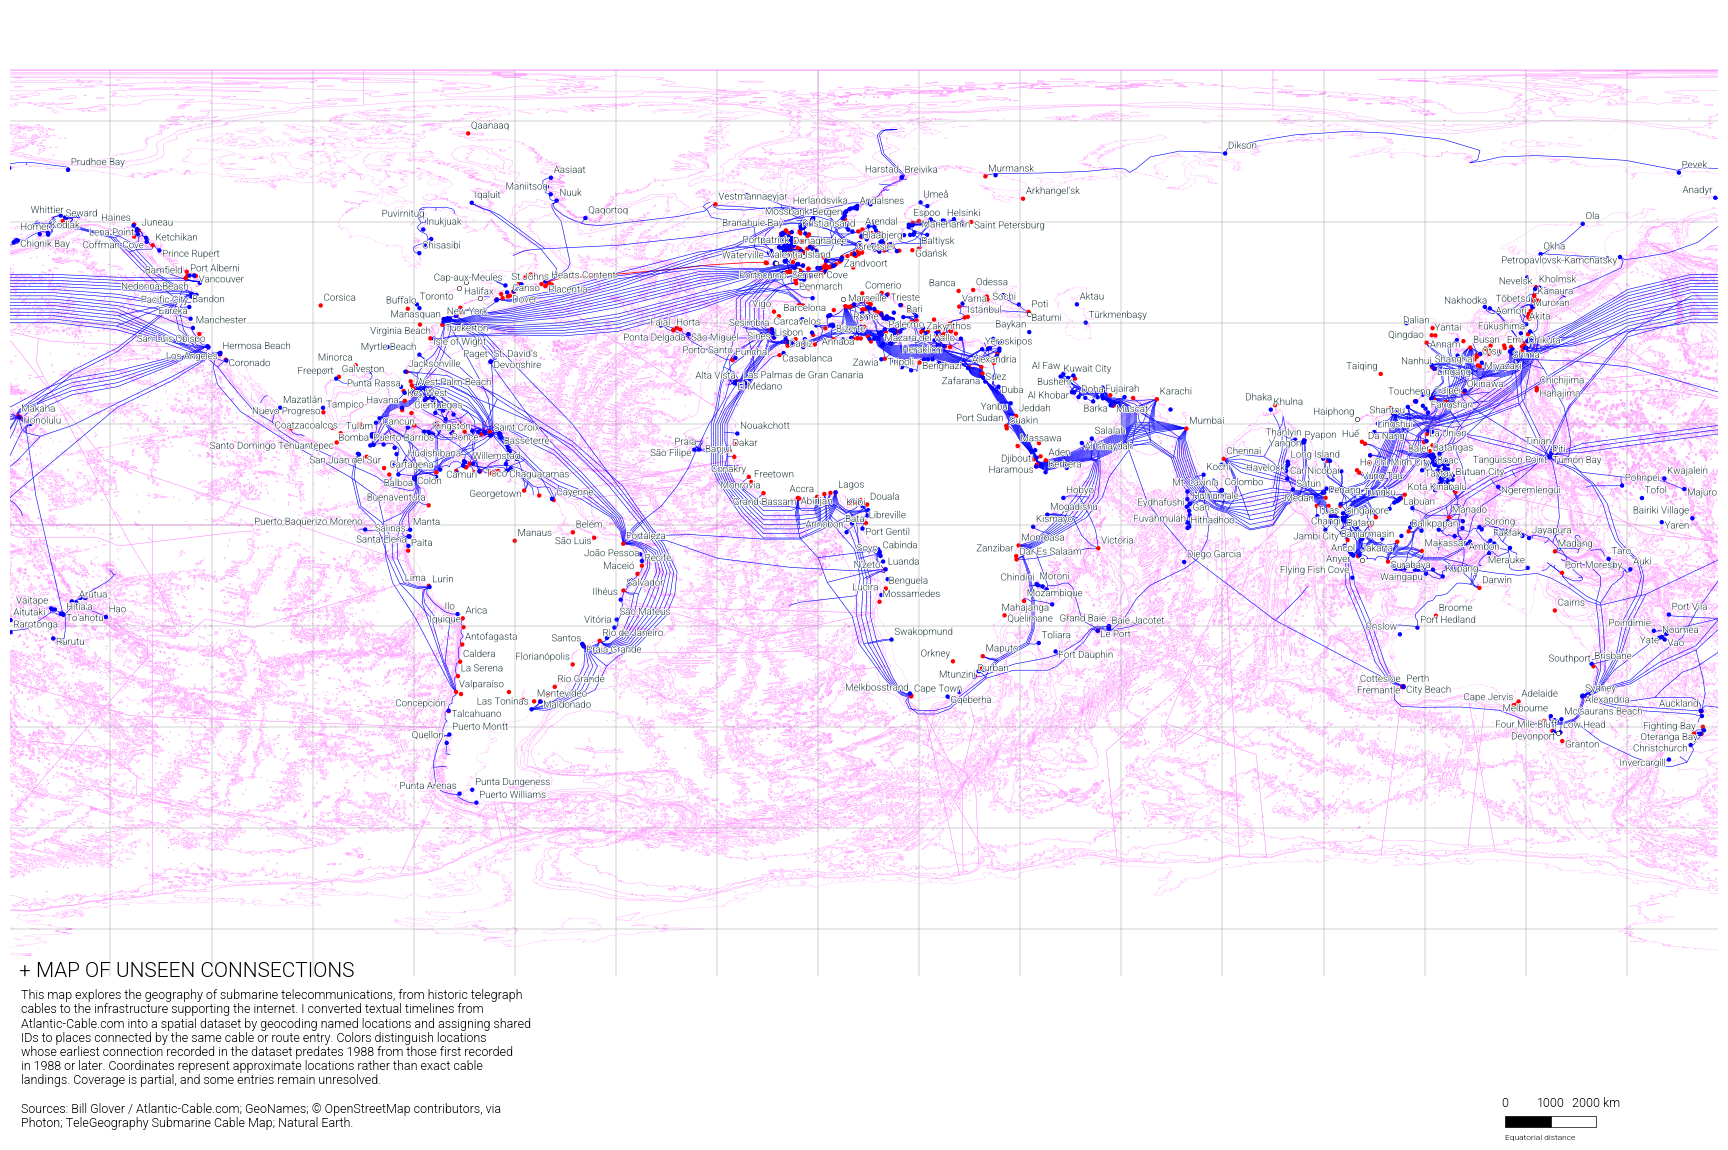

In [31]:
# create the same 17-by-11-inch landscape page as the reference
fig = plt.figure(figsize=(17, 11), facecolor="white")

# reproduce the map rectangle from the QGIS layout, including its page crop
map_left_mm, map_top_mm = 0.0, -9.60996
map_width_mm, map_height_mm = 433.927, 245.424
ax = fig.add_axes([
    map_left_mm / page_width_mm,
    1 - (map_top_mm + map_height_mm) / page_height_mm,
    map_width_mm / page_width_mm,
    map_height_mm / page_height_mm
])

# draw depth contours and coastlines in pink
bathymetry.boundary.plot(ax=ax, color="#ff8fff", linewidth=0.255, zorder=1)
land.boundary.plot(ax=ax, color="#ff8fff", linewidth=0.15, zorder=2)

# draw the digitized Atlantic cable and the supplied blue cable network
historical_cable.plot(ax=ax, color="#ff0000", linewidth=0.57, zorder=3)
cables.plot(ax=ax, color="#0000ff", linewidth=0.425, zorder=4)

# draw the historical locations, then the gray twenty-degree grid
for period, color in period_colors.items():
    subset = locations.loc[locations["period"].eq(period)]
    if not subset.empty:
        subset.plot(ax=ax, color=color, markersize=10,
                    edgecolor="black" if period == "Unknown year" else "none",
                    linewidth=0.4, zorder=5)
graticules.plot(ax=ax, color="#8d8d8d", linewidth=0.283, zorder=6)

# set the reference extent before placing labels
ax.set_xlim(map_bounds[0], map_bounds[2])
ax.set_ylim(map_bounds[1], map_bounds[3])
ax.set_aspect("equal", adjustable="box")
ax.set_axis_off()
label_count = label_locations(ax, locations)

# add the narrative and scale to the completed map
add_map_details(fig)

# export the newly constructed figure without changing the reference PDF
with plt.rc_context({"savefig.bbox": None}):
    fig.savefig(output_pdf, format="pdf", dpi=300)
print("Placed city labels:", label_count)
print("Saved:", output_pdf)
plt.show()


In [32]:
# save the rebuilt and classified point layer for reuse
locations_path = derived_dir / "historical_cable_locations.geojson"
locations.to_file(locations_path, driver="GeoJSON")
location_table_path = derived_dir / "historical_cable_locations.csv"
locations.drop(columns="geometry").to_csv(location_table_path, index=False)
print("Saved:", locations_path)
print("Saved:", location_table_path)


Saved: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignments/Assignment 02 Making Data + Narrative Building/Output/historical_cable_locations.geojson
Saved: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignments/Assignment 02 Making Data + Narrative Building/Output/historical_cable_locations.csv
